---
title: "Issued 31 October 2023: a five-model dekad ensemble"
subtitle: "Five subseasonal models calibrated with CCA and PCR for the next three dekads, averaged, and turned into a flexible forecast"
description: "Five SubX models answering a forecast issued on 31 October 2023, each calibrated against CHIRPS v3.0 at 0.05 degree for dekad +1 to dekad +3, combined into a multi-model ensemble: the start rule, skill of every member and of the ensemble, EOF and CCA patterns, calibrated forecasts, and probability of exceedance."
---

## 1. The question, the models and the start rule

The [dekad single-model case](dekad-leads-2023.ipynb) calibrated GEFSv12 for the next
three dekads after an issue date on the last day of a dekad. This notebook asks
the same of **every subseasonal model that can answer it** and averages the calibrated
forecasts. It follows the [weekly ensemble](week-mme-2023.ipynb), which explains the
choices in full; only what differs for dekads is repeated here.

The targets are calendar dekads, observed with CHIRPS v3.0's own dekad product. A dekad is 8 to 11 days long.
The forecast is issued on **31 October 2023** for dekad +1 to dekad +3, 1 to 30 November 2023.

Five SubX models have hindcasts and 2023 runs with values: GEFSv12, CFSv2, GEOS_V2p1,
CCSM4 and FIMr1p1. Training uses **October-December targets of 2000-2016**, the years
all five hindcast sets share. The single-model case used 2000-2018.

Two rules decide which run of each model is used:

- **Training.** GEFSv12 hindcasts start on Wednesdays only. As in the single-model
  case, each training target and lead uses the one Wednesday whose distance from the
  target falls in that lead's 7-day window (1 to 7 days before the dekad for dekad +1, 8 to 14 for dekad +2 and 18 to 24 for dekad +3). That Wednesday is the
  issue date of the training sample.
- **Every model answers an issue date with its latest run on or before it, at most 6
  days earlier**, in training and in 2023. The target is the same calendar dekad for
  every model, so a model that started earlier is used at a longer lead. CFSv2 is the
  mean of its four six-hourly runs up to 00 UTC on the issue date.

A model is a member at a lead only if its 2023 run reaches the target and it has a run
for at least 90% of the training targets. FIMr1p1 forecasts 32 days, so it cannot
reach dekad +3.

`research/scripts/subseasonal_mme_fits.py` prepares everything below with these rules.

In [1]:
from pathlib import Path
import datetime as dt
import gzip
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import norm, t as student_t

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import subseasonal_skill_scan as scan           # the start rule
import subseasonal_mme_fits as mme_fits         # preparation and the parallel CPT fits
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-issued-2023-10-31-dekads-mme"
data_dir = repo / "docs/data/dekad-mme-2023"
assets = repo / "docs/assets/dekad-mme-2023"
issue = pd.Timestamp("2023-10-31")
models = list(mme_fits.MODELS)
short = lambda m: {"GEFSv12_CPC": "GEFSv12", "GEOS_V2p1": "GEOS", "FIMr1p1": "FIM", "MME": "MME"}.get(m, m)

start = time.monotonic()
meta = mme_fits.prepare_calendar("dekads", case_root, issue.date())
print(f"Prepared in {time.monotonic() - start:.0f} s")
leads = list(meta["leads"])                      # lead1, lead2, ...: dekad +1 to dekad +3
number = {lead: i + 1 for i, lead in enumerate(leads)}
members = {lead: meta["leads"][lead].get("models", models) for lead in leads}
rows = []
for m in models:
    r = meta["runs"][m]
    rows.append({"model": short(m), "2023 run used": ", ".join(s.replace("T", " ") for s in r["starts"]) if len(r["starts"]) == 1 else f"{r['starts'][0].replace('T', ' ')} to {r['starts'][-1].replace('T', ' ')} (4 runs)",
                 "members, 2023": r["members"], "days behind the issue, 2023": r["lag_days"],
                 "members, training": r["training_members"], "days behind, training (min / mean / max)": " / ".join(f"{v:g}" for v in r["training_lag_days"])})
start_rule = pd.DataFrame(rows).set_index("model")
start_rule

2023 runs for the issue of 2023-10-31: GEFSv12_CPC 2023-10-31 (31 members, lag 0 d); CFSv2 2023-10-31 (16 members, lag 0 d); GEOS_V2p1 2023-10-28 (4 members, lag 3 d); CCSM4 2023-10-29 (9 members, lag 2 d); FIMr1p1 2023-10-25 (4 members, lag 6 d)


observations: 153 training targets read in 517 s; pixels touching Indonesia 70,213, with data in every training target 69,638


lead1: 5 members (GEFSv12_CPC, CFSv2, GEOS_V2p1, CCSM4, FIMr1p1); 152 of 153 training targets on all of them; 2023 target 01 Nov to 10 Nov


lead2: 5 members (GEFSv12_CPC, CFSv2, GEOS_V2p1, CCSM4, FIMr1p1); 151 of 153 training targets on all of them; 2023 target 11 Nov to 20 Nov


lead3: 4 members (GEFSv12_CPC, CFSv2, GEOS_V2p1, CCSM4); 150 of 153 training targets on all of them; 2023 target 21 Nov to 30 Nov; not members: {'FIMr1p1': 'no 2023 forecast this far ahead'}


Prepared in 717 s


,2023 run used,"members, 2023","days behind the issue, 2023","members, training","days behind, training (min / mean / max)"
model,,,,,
GEFSv12,2023-10-31 00:00,31,0.0,11,0 / 0 / 0
CFSv2,2023-10-30 06:00 to 2023-10-31 00:00 (4 runs),16,0.0,4,0 / 0 / 0
GEOS,2023-10-28 00:00,4,3.0,4,0 / 1.83 / 4
CCSM4,2023-10-29 00:00,9,2.0,3,0 / 2.09 / 5
FIM,2023-10-25 00:00,4,6.0,4,0 / 0 / 0


The 2023 runs have more members than the hindcasts for GEFSv12 (31 against 11),
CFSv2 (16 against 4) and CCSM4 (9 against 3), so the 2023 ensemble means are less
noisy than the ones the calibration was trained on. The lag columns show how far
behind the issue date each model's run was, in 2023 and across the training samples.

In [2]:
membership = pd.DataFrame([{"lead": meta["leads"][lead]["name"], "target": f"{meta['leads'][lead]['target_first_day']} to {meta['leads'][lead]['target_last_day']}",
                            "days": meta["leads"][lead]["days"], "members": ", ".join(short(m) for m in members[lead]),
                            "not members": "; ".join(f"{short(m)}: {why}" for m, why in meta["leads"][lead].get("not_members", {}).items()) or "none",
                            "training targets": len(meta["leads"][lead]["training_targets"])} for lead in leads]).set_index("lead")
membership

,target,days,members,not members,training targets
lead,,,,,
Dekad +1,2023-11-01 to 2023-11-10,10,"GEFSv12, CFSv2, GEOS, CCSM4, FIM",none,152
Dekad +2,2023-11-11 to 2023-11-20,10,"GEFSv12, CFSv2, GEOS, CCSM4, FIM",none,151
Dekad +3,2023-11-21 to 2023-11-30,10,"GEFSv12, CFSv2, GEOS, CCSM4",FIM: no 2023 forecast this far ahead,150


## 2. 28 fits

Each member is calibrated for each lead with **CCA** (3 predictor EOFs, 3 predictand
EOFs, 2 CCA modes) and **PCR** (3 predictor EOFs), the settings of the single-model
case. Both fields are anomalies from a mean over the training years (one target per
year, the nearest in season day), and the samples are re-dated to placeholder years
because CPT cannot read an irregular time axis. The cross-validation window is
17 samples: a year holds 9 targets, so a left-out target's neighbours within
about a year are left out with it.

Every member at a given lead is trained on **the same targets**, the ones all of that
lead's members have a run for. Each fit is its own process and keeps a compact result
at the Indonesian pixels; a finished fit is reused when its inputs and settings are
unchanged. At 0.05° a CCA fit takes about an hour.

In [3]:
jobs = mme_fits.jobs_for(case_root, meta)
start = time.monotonic()
fit_records = mme_fits.run(jobs, workers=25, log=lambda line: None)
failed = [r for r in fit_records if r["status"] == "failed"]
assert not failed, failed[:3]
fits = pd.DataFrame(fit_records)
print(f"{len(fits)} fits: {dict(fits['status'].value_counts())}; this run took {(time.monotonic() - start) / 60:.1f} min")
print(f"Minutes per fit when fitted: CCA {fits[fits.method == 'CCA'].seconds.min() / 60:.0f} to {fits[fits.method == 'CCA'].seconds.max() / 60:.0f}, "
      f"PCR {fits[fits.method == 'PCR'].seconds.min() / 60:.0f} to {fits[fits.method == 'PCR'].seconds.max() / 60:.0f}")
fits.assign(minutes=(fits["seconds"] / 60).round(1), model=fits["model"].map(short)).pivot_table(
    index=["model", "method"], columns="lead", values="minutes")[leads].reindex([short(m) for m in models], level=0)

28 fits: {'reused': np.int64(28)}; this run took 0.5 min
Minutes per fit when fitted: CCA 60 to 73, PCR 26 to 31


lead            lead1  lead2  lead3
model   method                     
GEFSv12 CCA      72.5   66.5   62.0
        PCR      25.6   26.7   26.4
CFSv2   CCA      70.5   64.8   60.5
        PCR      25.6   29.0   29.1
GEOS    CCA      64.2   69.9   62.7
        PCR      29.3   27.4   28.3
CCSM4   CCA      63.5   63.2   70.2
        PCR      28.8   29.1   28.5
FIM     CCA      68.8   63.1    NaN
        PCR      30.9   26.7    NaN

## 3. Load the results and build the ensemble

Everything below works on plain arrays with one value per kept pixel, in a fixed
pixel order (north to south, west to east).

The ensemble is built as PyCPT's `construct_mme` builds it: the **equal-weight mean**
of the members' cross-validated hindcasts, deterministic forecasts, prediction error
variances and tercile probabilities. Its Pearson correlation and 2AFC are then
computed from its hindcasts. Two checks come first: CPT's own Pearson map of each
member equals the correlation recomputed from its hindcasts, and the 2AFC function
used for the ensemble reproduces CPT's 2AFC map of a member.

In [4]:
inputs = case_root / "inputs"
with xr.open_dataset(inputs / "mask.nc") as m:
    grid_mask = m["mask"].load()
grid_Y, grid_X = grid_mask["Y"], grid_mask["X"]
flat = np.flatnonzero(grid_mask.values.ravel())
n = len(flat)
pixel_lat = np.repeat(grid_Y.values, grid_mask.sizes["X"])[flat]
pixel_lon = np.tile(grid_X.values, grid_mask.sizes["Y"])[flat]
weight = np.cos(np.deg2rad(pixel_lat))


def at_pixels(a):
    # A (..., Y, X) DataArray on the predictand grid -> (..., pixel) array.
    a = a.transpose(..., "Y", "X")
    return a.values.reshape(a.shape[:-2] + (-1,))[..., flat].astype("float64")


def field(values):
    # (pixel,) array -> (Y, X) DataArray for mapping.
    full = np.full(grid_mask.size, np.nan)
    full[flat] = values
    return xr.DataArray(full.reshape(grid_mask.shape), coords={"Y": grid_Y, "X": grid_X}, dims=("Y", "X"))


def area_mean(values):
    ok = np.isfinite(values)
    return float((values[ok] * weight[ok]).sum() / weight[ok].sum())


def corr(a, b):
    a, b = a - a.mean(0), b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a * a).sum(0) * (b * b).sum(0))


def two_afc(hindcast, observed):
    # Chance (%) that the hindcasts rank two targets with different observations in the observed order; ties count half.
    right, pairs = np.zeros(observed.shape[1]), np.zeros(observed.shape[1])
    for i in range(observed.shape[0] - 1):
        d_o, d_h = observed[i + 1:] - observed[i], hindcast[i + 1:] - hindcast[i]
        differ = d_o != 0
        right += ((d_o * d_h) > 0).sum(0) + 0.5 * ((d_h == 0) & differ).sum(0)
        pairs += differ.sum(0)
    return right / pairs * 100


start = time.monotonic()
target_dates = {lead: pd.DatetimeIndex(meta["leads"][lead]["training_targets"]) for lead in leads}
target_years = {lead: target_dates[lead].year.values for lead in leads}
obs = {}
for lead in leads:
    with xr.open_dataarray(inputs / f"Y-{lead}.nc") as y:
        obs[lead] = at_pixels(y.load())                     # training anomalies, (target, pixel)
with xr.open_dataset(inputs / "targets-2023.nc") as ds:
    extra = {v: at_pixels(ds[v].load()) for v in ds.data_vars}
names = {lead: members[lead] + ["MME"] for lead in leads}
res, patterns = {}, {}
for lead in leads:
    for m in members[lead]:
        for method in ("CCA", "PCR"):
            with xr.open_dataset(case_root / "compact" / f"{lead}-{m}-{method}.nc") as ds:
                res[lead, m, method] = dict(h=ds.cv_hindcast.values, f=ds.forecast.values.astype("float64"), p=ds.forecast_probability.values.astype("float64"),
                                            pev=ds.forecast_pev.values.astype("float64"), pearson=ds.skill_pearson.values.astype("float64"),
                                            afc=ds.skill_two_alternative_forced_choice.values.astype("float64"), attrs=dict(ds.attrs))
                assert (ds["pixel"].values == flat).all()
                if method == "CCA":
                    patterns[lead, m] = ds[[v for v in ds.data_vars if v[:2] in ("x_", "y_")]].load()
    for method in ("CCA", "PCR"):
        mine = [res[lead, m, method] for m in members[lead]]
        h = np.mean([r["h"] for r in mine], axis=0, dtype="float64")
        res[lead, "MME", method] = dict(h=h, f=np.mean([r["f"] for r in mine], axis=0), p=np.mean([r["p"] for r in mine], axis=0),
                                        pev=np.mean([r["pev"] for r in mine], axis=0), pearson=corr(h, obs[lead]), afc=two_afc(h, obs[lead]))
print(f"Loaded {len(res)} results at {n:,} pixels in {time.monotonic() - start:.0f} s")

gaps = {"CPT Pearson minus recomputed, members": max(float(res[lead, m, method]["attrs"]["largest_gap_cpt_vs_recomputed_pearson"])
                                                    for lead in leads for m in members[lead] for method in ("CCA", "PCR")),
        "CPT 2AFC minus this notebook's 2AFC, GEFSv12 CCA (percentage points)": max(
            float(np.nanmax(abs(res[lead, "GEFSv12_CPC", "CCA"]["afc"] - two_afc(res[lead, "GEFSv12_CPC", "CCA"]["h"].astype("float64"), obs[lead])))) for lead in leads),
        "hindcast values missing": sum(int(res[lead, m, method]["attrs"]["hindcast_values_missing"]) for lead in leads for m in members[lead] for method in ("CCA", "PCR")),
        "MME probabilities: largest distance of their sum from 100": max(float(np.nanmax(abs(res[lead, "MME", method]["p"].sum(0) - 100))) for lead in leads for method in ("CCA", "PCR"))}
pd.Series(gaps, name="largest absolute difference").to_frame()

Loaded 34 results at 69,638 pixels in 634 s


,largest absolute difference
"CPT Pearson minus recomputed, members",0.000001
"CPT 2AFC minus this notebook's 2AFC, GEFSv12 CCA (percentage points)",0.460378
hindcast values missing,0.000000
MME probabilities: largest distance of their sum from 100,0.000004


## 4. Skill of every member and of the ensemble

Four scores, each computed at every pixel and summarised as an area-weighted mean
(weights: cosine of latitude):

- **Pearson correlation** of the cross-validated hindcasts with the observed
  anomalies (CPT's map for the members).
- **2AFC**: the chance that the hindcasts rank two different targets in the observed
  order, 50% for no skill.
- **Raw correlation**: the model's own rainfall anomaly, interpolated to the pixels,
  against the observed anomaly. No fitting is involved.
- **Cross-validated RPSS** of tercile probabilities. CPT's own probabilistic scores
  come from in-sample probabilities, so they are not used. For each training year the
  notebook leaves out **every target of that year**, takes the tercile boundaries
  (33rd and 67th percentiles, Hazen rule) from the remaining observations and the
  error spread from the remaining cross-validated errors, and gives each left-out
  target a Student's t distribution centred on its cross-validated hindcast. The
  ranked probability score is compared with a **forecast with no model put through
  the same steps**: for a target, the mean of the other years' anomalies. Above 0
  means the model adds information. This construction is this tutorial's, not CPT's.

In [5]:
def no_model(observed, years):
    # The forecast with no model: for each target, the mean of the observations of the other years.
    return np.stack([observed[years != y].mean(0) for y in years])


start = time.monotonic()
reference_rps = {lead: scan.cv_rps(no_model(obs[lead], target_years[lead]), obs[lead], target_years[lead]) for lead in leads}
raw = {}
points = dict(Y=xr.DataArray(pixel_lat, dims="pixel"), X=xr.DataArray(pixel_lon, dims="pixel"))
for lead in leads:
    for m in members[lead]:
        with xr.open_dataarray(inputs / f"X-{lead}-{m}.nc") as x:
            raw[lead, m] = x.load().interp(**points, method="linear").transpose("T", "pixel").values.astype("float64")
    raw[lead, "MME"] = np.mean([raw[lead, m] for m in members[lead]], axis=0)

first_day = {lead: pd.Timestamp(meta["leads"][lead]["target_first_day"]) for lead in leads}
last_day = {lead: pd.Timestamp(meta["leads"][lead]["target_last_day"]) for lead in leads}
label = {lead: f"{first_day[lead].day}-{last_day[lead].day} {last_day[lead]:%b %Y}" for lead in leads}
lead_name = {lead: meta["leads"][lead]["name"] for lead in leads}

rows = []
for lead in leads:
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            r["rpss"] = 1 - scan.cv_rps(r["h"].astype("float64"), obs[lead], target_years[lead]) / reference_rps[lead]
            rows.append({"lead": number[lead], "target": label[lead], "model": short(name), "method": method,
                         "Pearson": area_mean(r["pearson"]), "2AFC (%)": area_mean(r["afc"]), "CV RPSS": area_mean(r["rpss"])})
        res[lead, name, "raw"] = dict(pearson=corr(raw[lead, name], obs[lead]))
        rows.append({"lead": number[lead], "target": label[lead], "model": short(name), "method": "raw",
                     "Pearson": area_mean(res[lead, name, "raw"]["pearson"])})
skill_table = pd.DataFrame(rows).set_index(["lead", "model", "method"]).sort_index()
print(f"Scores in {time.monotonic() - start:.0f} s")
# Cross-validation makes a forecast with no model correlate negatively with the observations
# (leaving a wet year out lowers the mean of the rest), so 0 is not the no-skill level of a
# cross-validated correlation. The same no-model forecast is the RPSS reference.
no_model_pearson = {lead: area_mean(corr(no_model(obs[lead], target_years[lead]), obs[lead])) for lead in leads}
print("Area-weighted mean Pearson of the no-model forecast (other years' mean), by lead:", {lead: round(v, 3) for lead, v in no_model_pearson.items()})
skill_table["Pearson"].unstack("lead").round(3)

Scores in 1802 s


Area-weighted mean Pearson of the no-model forecast (other years' mean), by lead: {'lead1': -0.469, 'lead2': -0.469, 'lead3': -0.467}


lead                1      2      3
model   method                     
CCSM4   CCA     0.306  0.252  0.227
        PCR     0.299  0.238  0.215
        raw     0.259  0.209  0.197
CFSv2   CCA     0.327  0.219  0.158
        PCR     0.315  0.218  0.154
        raw     0.342  0.262  0.192
FIM     CCA     0.334  0.251    NaN
        PCR     0.326  0.252    NaN
        raw     0.359  0.266    NaN
GEFSv12 CCA     0.360  0.323  0.173
        PCR     0.354  0.322  0.171
        raw     0.429  0.335  0.211
GEOS    CCA     0.308  0.236  0.093
        PCR     0.306  0.242  0.074
        raw     0.327  0.256  0.222
MME     CCA     0.369  0.302  0.202
        PCR     0.370  0.312  0.200
        raw     0.457  0.373  0.287

In [6]:
skill_table["CV RPSS"].dropna().unstack("lead").round(3)

lead                1      2      3
model   method                     
CCSM4   CCA     0.089  0.074  0.060
        PCR     0.088  0.070  0.058
CFSv2   CCA     0.102  0.061  0.038
        PCR     0.099  0.060  0.036
FIM     CCA     0.102  0.075    NaN
        PCR     0.102  0.073    NaN
GEFSv12 CCA     0.112  0.094  0.047
        PCR     0.111  0.095  0.045
GEOS    CCA     0.093  0.068  0.031
        PCR     0.092  0.070  0.023
MME     CCA     0.117  0.091  0.056
        PCR     0.120  0.096  0.057

The same numbers as a chart: one line per member, the ensemble in black, for CCA and
for PCR. The dashed grey line is the raw multi-model mean, with no calibration.

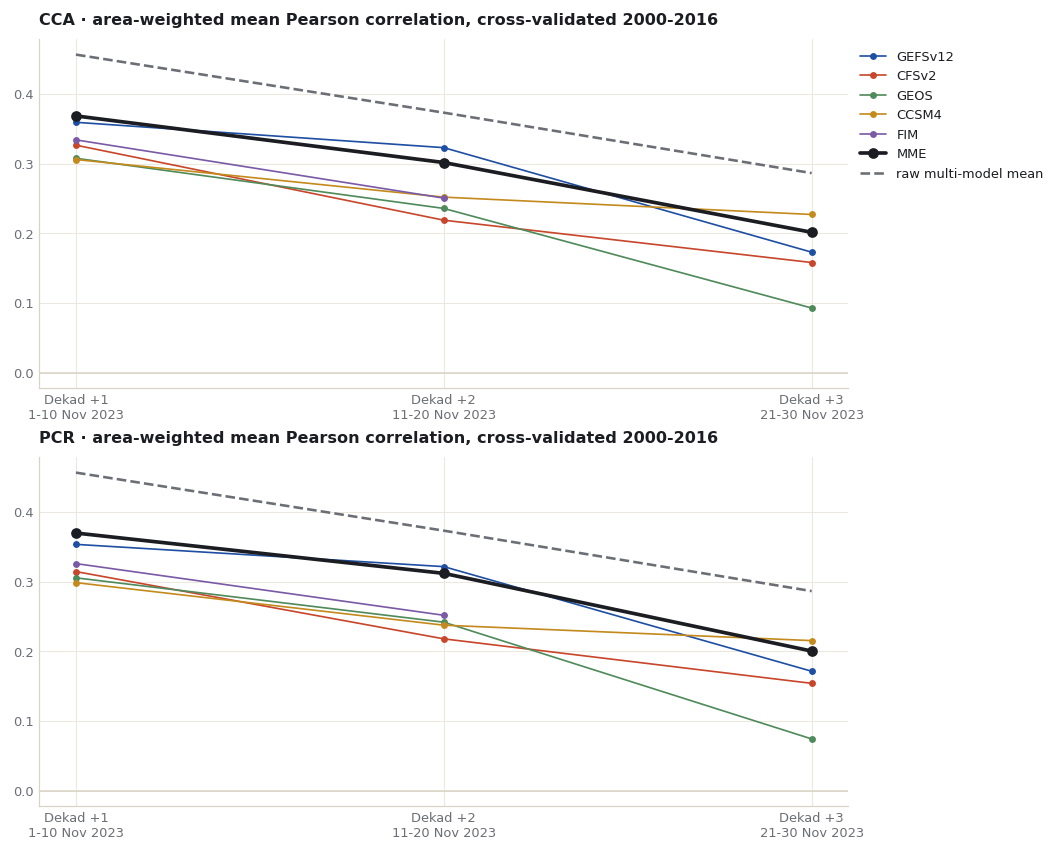

In [7]:
order = [number[lead] for lead in leads]
model_colours = dict(zip([short(m) for m in models], figures.CYCLE))
fig, grid = figures.stacked([3.3, 3.3], width=figures.MAP_WIDTH)
for row, method in enumerate(["CCA", "PCR"]):
    ax = fig.add_subplot(grid[row, 0])
    ax.axhline(0, color=figures.LINE, linewidth=1)
    for m in models:
        which = [number[lead] for lead in leads if m in members[lead]]
        ax.plot(which, [skill_table.loc[(k, short(m), method), "Pearson"] for k in which], "-o", markersize=3.5, linewidth=1.1,
                color=model_colours[short(m)], label=short(m))
    ax.plot(order, [skill_table.loc[(k, "MME", method), "Pearson"] for k in order], "-o", color=figures.INK, linewidth=2.4, label="MME")
    ax.plot(order, [skill_table.loc[(k, "MME", "raw"), "Pearson"] for k in order], "--", color=figures.MUTED, label="raw multi-model mean")
    ax.set_xticks(order, [f"{lead_name[lead]}\n{label[lead]}" for lead in leads])
    ax.set_title(f"{method} · area-weighted mean Pearson correlation, cross-validated 2000-2016")
    if row == 0:
        ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "pearson-by-lead-models.png")
plt.show()

Did combining help? For each lead: the ensemble against GEFSv12 alone (the model of
the single-model case) and against the best single member, and the share of the area
where the ensemble's correlation is higher than GEFSv12's.

In [8]:
rows = []
for lead in leads:
    for method in ("CCA", "PCR"):
        member_scores = {short(m): skill_table.loc[(number[lead], short(m), method), "Pearson"] for m in members[lead]}
        best = max(member_scores, key=member_scores.get)
        mme, gefs = res[lead, "MME", method]["pearson"], res[lead, "GEFSv12_CPC", method]["pearson"]
        rows.append({"lead": number[lead], "target": label[lead], "method": method, "members": len(members[lead]),
                     "training targets": len(target_years[lead]),
                     "MME Pearson": area_mean(mme), "GEFSv12 Pearson": member_scores["GEFSv12"],
                     "best member": best, "best member Pearson": member_scores[best],
                     "raw multi-model mean Pearson": skill_table.loc[(number[lead], "MME", "raw"), "Pearson"],
                     "raw GEFSv12 Pearson": skill_table.loc[(number[lead], "GEFSv12", "raw"), "Pearson"],
                     "pixels where MME > GEFSv12 (%)": float((weight * (mme > gefs)).sum() / weight.sum() * 100),
                     "MME CV RPSS": skill_table.loc[(number[lead], "MME", method), "CV RPSS"],
                     "GEFSv12 CV RPSS": skill_table.loc[(number[lead], "GEFSv12", method), "CV RPSS"]})
gain = pd.DataFrame(rows).set_index(["lead", "method"])
gain.round(3)

target  members  training targets  MME Pearson  \
lead method                                                           
1    CCA      1-10 Nov 2023        5               152        0.369   
     PCR      1-10 Nov 2023        5               152        0.370   
2    CCA     11-20 Nov 2023        5               151        0.302   
     PCR     11-20 Nov 2023        5               151        0.312   
3    CCA     21-30 Nov 2023        4               150        0.202   
     PCR     21-30 Nov 2023        4               150        0.200   

             GEFSv12 Pearson best member  best member Pearson  \
lead method                                                     
1    CCA               0.360     GEFSv12                0.360   
     PCR               0.354     GEFSv12                0.354   
2    CCA               0.323     GEFSv12                0.323   
     PCR               0.322     GEFSv12                0.322   
3    CCA               0.173       CCSM4                0.227   
     PCR               0.171       CCSM4                0.215   

             raw multi-model mean Pearson  raw GEFSv12 Pearson  \
lead method                                                      
1    CCA                            0.457                0.429   
     PCR                            0.457                0.429   
2    CCA                            0.373                0.335   
     PCR                            0.373                0.335   
3    CCA                            0.287                0.211   
     PCR                            0.287                0.211   

             pixels where MME > GEFSv12 (%)  MME CV RPSS  GEFSv12 CV RPSS  
lead method                                                                
1    CCA                             61.674        0.117            0.112  
     PCR                             65.854        0.120            0.111  
2    CCA                             38.381        0.091            0.094  
     PCR                             47.170        0.096            0.095  
3    CCA                             77.421        0.056            0.047  
     PCR                             70.673        0.057            0.045

What each model contributes: the ensemble's correlation when one member is left out
(CCA). A value above the full ensemble's means the ensemble is better without that
model.

In [9]:
rows = []
for lead in leads:
    row = {"lead": number[lead], "target": label[lead], "all members": area_mean(res[lead, "MME", "CCA"]["pearson"])}
    for dropped in models:
        if dropped in members[lead]:
            rest = np.mean([res[lead, m, "CCA"]["h"] for m in members[lead] if m != dropped], axis=0, dtype="float64")
            row[f"without {short(dropped)}"] = area_mean(corr(rest, obs[lead]))
    rows.append(row)
leave_one_out = pd.DataFrame(rows).set_index("lead")
leave_one_out.round(3)

,target,all members,without GEFSv12,without CFSv2,without GEOS,without CCSM4,without FIM
lead,,,,,,,
1,1-10 Nov 2023,0.369,0.359,0.364,0.370,0.368,0.367
2,11-20 Nov 2023,0.302,0.275,0.306,0.304,0.300,0.306
3,21-30 Nov 2023,0.202,0.200,0.207,0.213,0.167,NaN


Where the ensemble's skill sits: the cross-validated correlation of the CCA ensemble
at each lead, in one column.

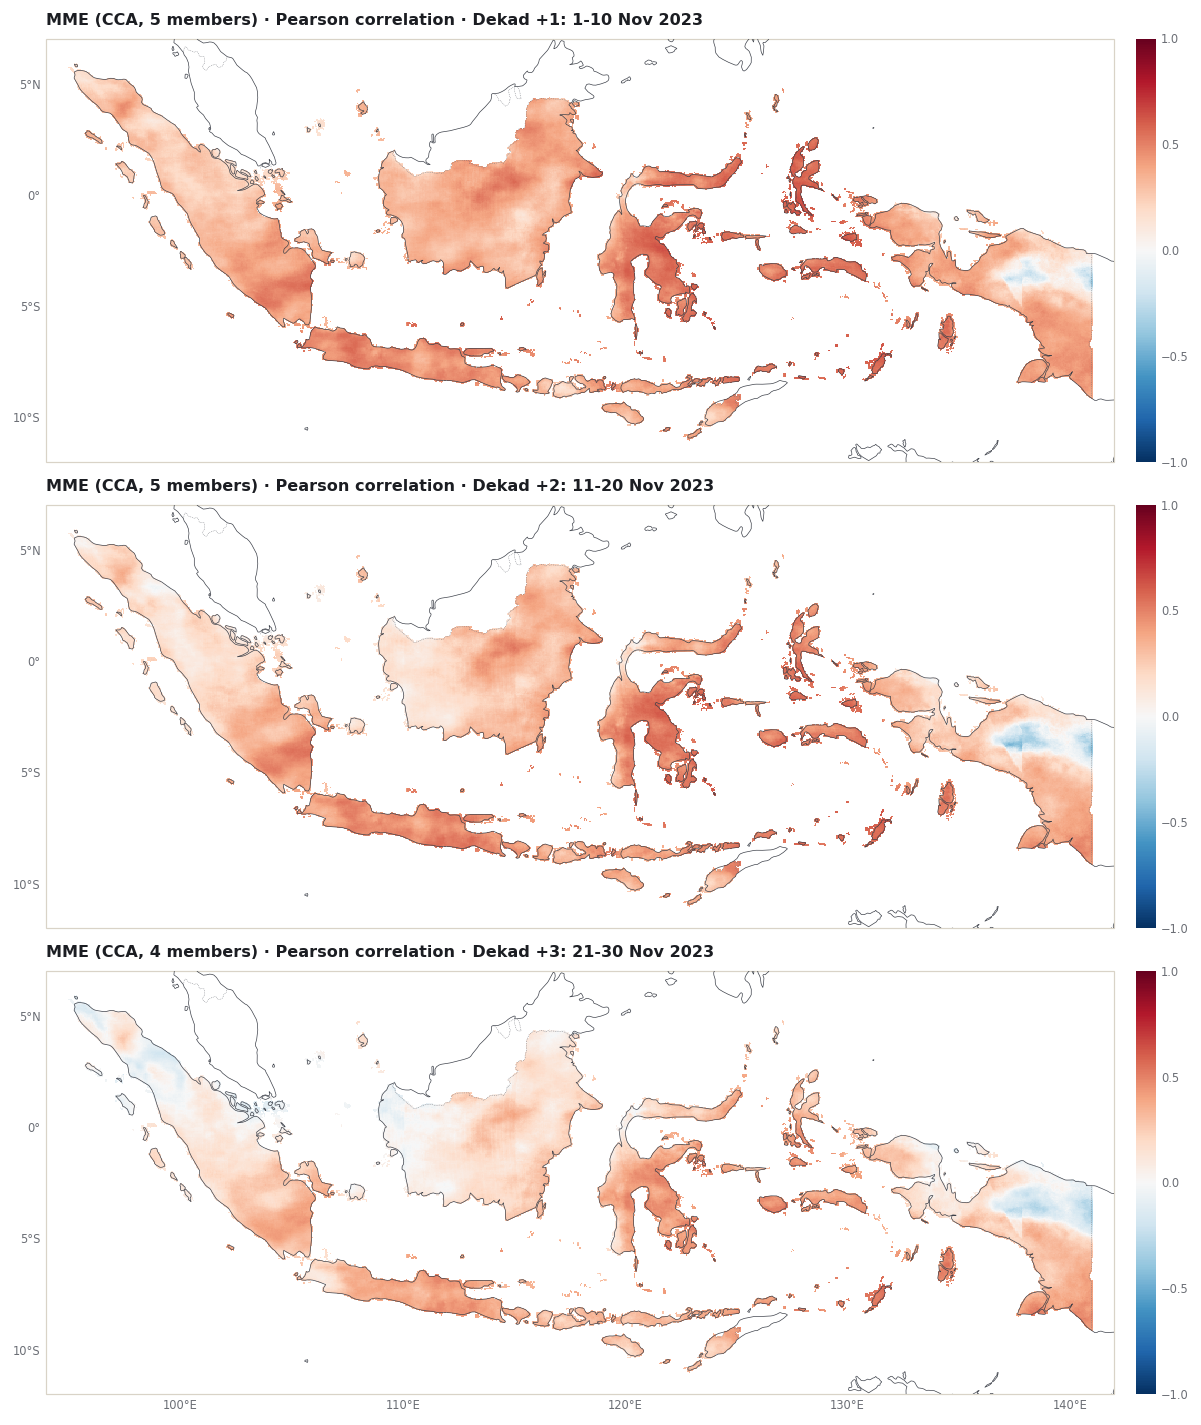

In [10]:
predictand_extent = {"west": float(grid_X.min()) - .025, "east": float(grid_X.max()) + .025, "south": float(grid_Y.min()) - .025, "north": float(grid_Y.max()) + .025}
predictor_extent = {k: float(v) for k, v in scan.BOX.items()}
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, field(res[lead, "MME", "CCA"]["pearson"]), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"MME (CCA, {len(members[lead])} members) · Pearson correlation · {lead_name[lead]}: {label[lead]}")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "mme-pearson-by-lead.png")
plt.show()

## 5. EOF patterns and CCA modes

CCA does not relate the two fields point by point. It first reduces each to a few
**EOFs** (patterns that explain the most variance from target to target, with a score
per target), then finds pairs of combinations of those, the **CCA modes**, whose score
series are as correlated as possible.

These patterns come from the fit to all training targets, not from the
cross-validation folds, so they describe the fitted model and are not evidence of
skill. The predictand EOFs depend on the observations alone, so they are the same for
every model at a given lead.

In [11]:
rows = []
for (lead, m), ds in patterns.items():
    row = {"lead": number[lead], "model": short(m)}
    for mode in (1, 2):
        xs, ys = ds.x_cca_scores.sel(Mode=mode).values, ds.y_cca_scores.sel(Mode=mode).values
        row[f"canonical correlation {mode}"] = float(np.corrcoef(xs, ys)[0, 1])
    for mode in (1, 2, 3):
        row[f"X EOF {mode} (%)"] = float(ds.x_explained_variance.sel(Mode=mode))
    for mode in (1, 2, 3):
        row[f"Y EOF {mode} (%)"] = float(ds.y_explained_variance.sel(Mode=mode))
    rows.append(row)
mode_table = pd.DataFrame(rows).set_index(["lead", "model"]).sort_index()
same_y = max(float(np.nanmax(abs(abs(patterns[lead, m].y_eof_loadings.values) - abs(patterns[lead, "GEFSv12_CPC"].y_eof_loadings.values))))
             for lead in leads for m in members[lead])
print(f"Predictand EOF loadings, largest difference between models at the same lead (sign ignored): {same_y:.2e}")
mode_table.round(2)

Predictand EOF loadings, largest difference between models at the same lead (sign ignored): 0.00e+00


canonical correlation 1  canonical correlation 2  X EOF 1 (%)  \
lead model                                                                    
1    CCSM4                       0.71                     0.54        13.40   
     CFSv2                       0.77                     0.48        10.03   
     FIM                         0.78                     0.52        11.46   
     GEFSv12                     0.79                     0.57        15.05   
     GEOS                        0.78                     0.47        14.22   
2    CCSM4                       0.72                     0.37        15.02   
     CFSv2                       0.68                     0.31        12.84   
     FIM                         0.75                     0.38        13.85   
     GEFSv12                     0.75                     0.52        19.41   
     GEOS                        0.71                     0.34        15.19   
3    CCSM4                       0.63                     0.35        15.11   
     CFSv2                       0.61                     0.27        13.45   
     GEFSv12                     0.64                     0.29        18.04   
     GEOS                        0.59                     0.22        16.94   

              X EOF 2 (%)  X EOF 3 (%)  Y EOF 1 (%)  Y EOF 2 (%)  Y EOF 3 (%)  
lead model                                                                     
1    CCSM4           9.07         5.73        25.09         9.22         5.99  
     CFSv2           8.94         7.02        25.09         9.22         5.99  
     FIM             7.77         5.92        25.09         9.22         5.99  
     GEFSv12        10.62         9.16        25.09         9.22         5.99  
     GEOS            7.81         6.71        25.09         9.22         5.99  
2    CCSM4          10.31         5.74        25.11         9.25         5.98  
     CFSv2          10.99         6.72        25.11         9.25         5.98  
     FIM             7.68         5.34        25.11         9.25         5.98  
     GEFSv12        11.71         7.86        25.11         9.25         5.98  
     GEOS            8.41         7.00        25.11         9.25         5.98  
3    CCSM4          10.46         5.38        24.94         9.26         6.03  
     CFSv2          11.75         6.39        24.94         9.26         6.03  
     GEFSv12        10.22         7.45        24.94         9.26         6.03  
     GEOS            7.87         5.50        24.94         9.26         6.03

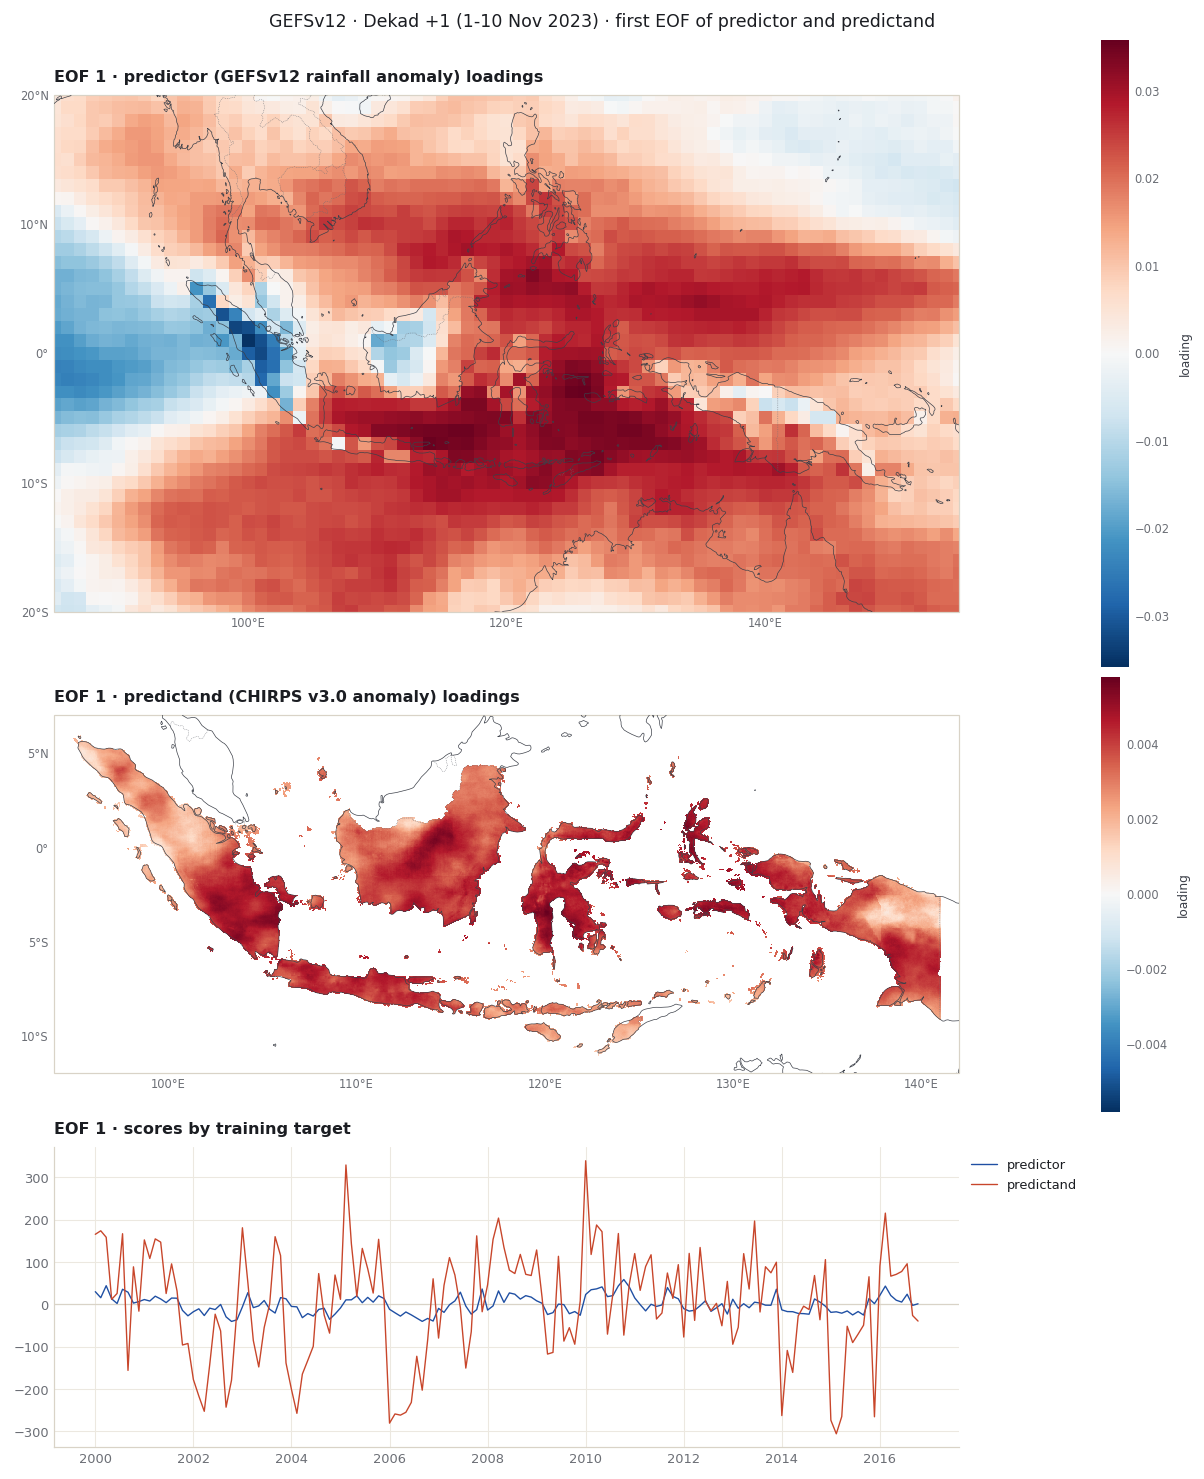

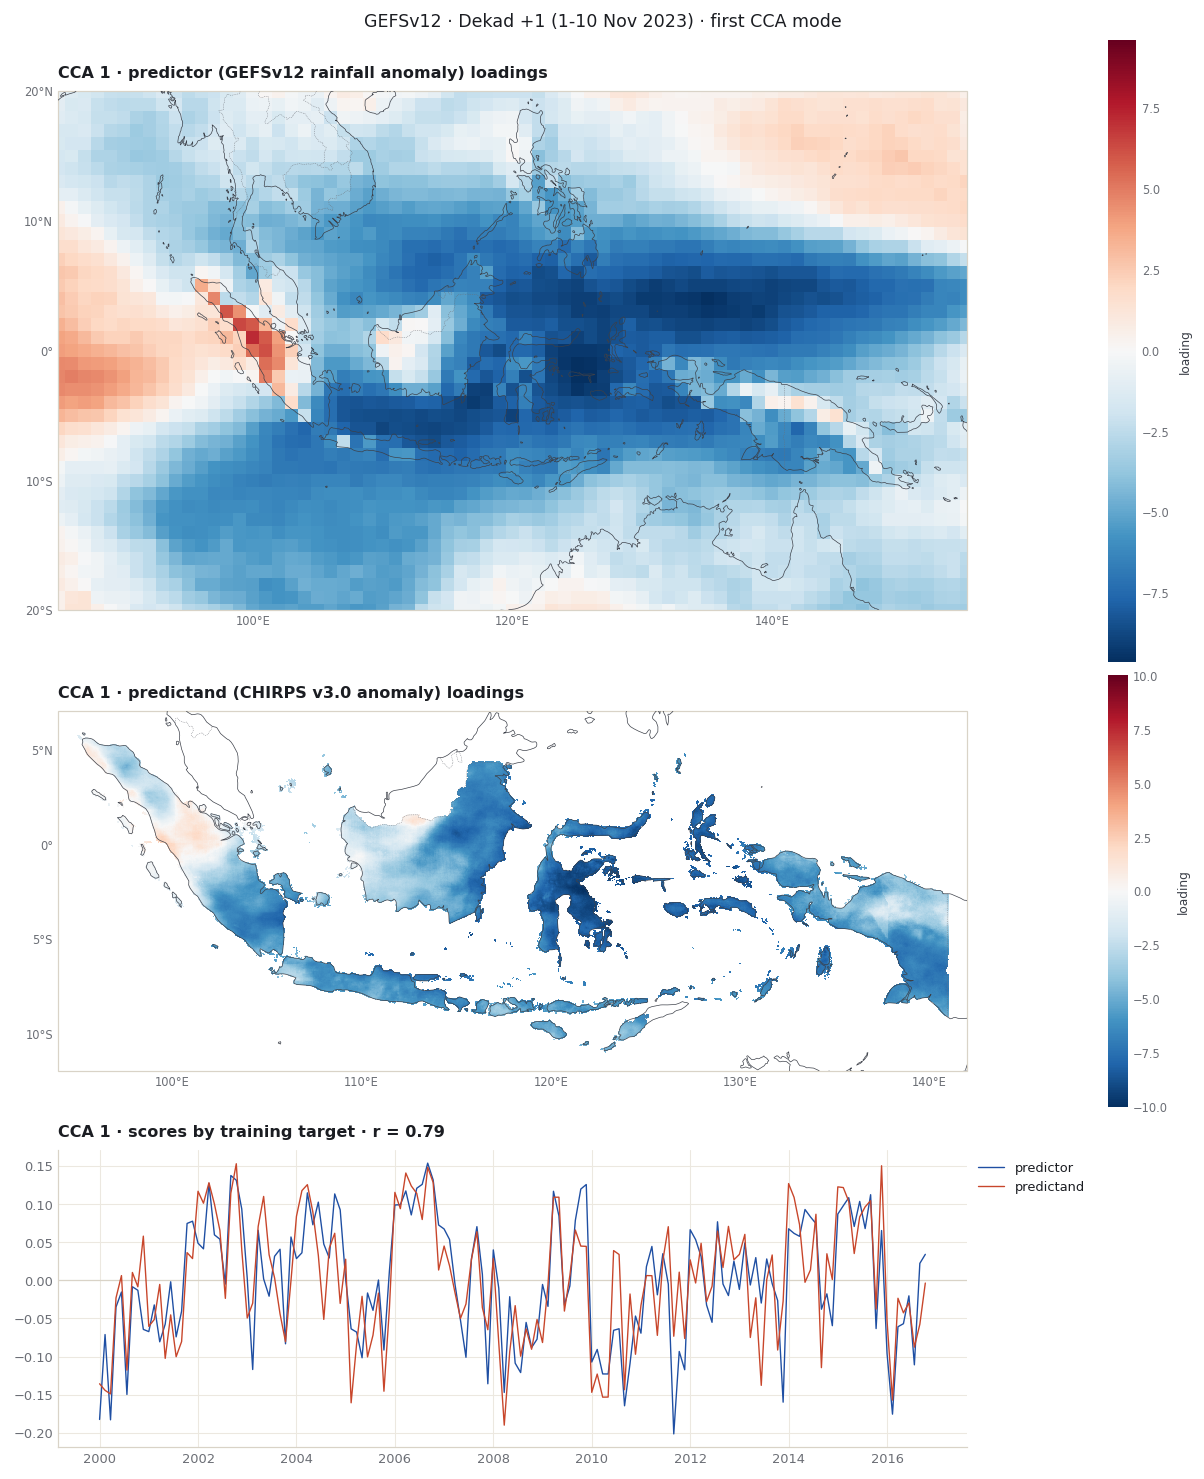

In [12]:
first_lead = leads[0]
ds = patterns[first_lead, "GEFSv12_CPC"]
predictor_box = figures.extent_of(predictor_extent)
for kind, file in (("eof", "eof1-gefs-lead1.png"), ("cca", "cca1-gefs-lead1.png")):
    fig, grid = figures.stacked([figures.map_height(predictor_box), figures.map_height(predictand_box), 2.6])
    x_load = ds[f"x_{kind}_loadings"].sel(Mode=1).rename({"Yx": "Y", "Xx": "X"})
    y_load = field(ds[f"y_{kind}_loadings"].sel(Mode=1).values.astype("float64"))
    for row, (load, box, side) in enumerate([(x_load, predictor_box, "predictor (GEFSv12 rainfall anomaly)"), (y_load, predictand_box, "predictand (CHIRPS v3.0 anomaly)")]):
        limit = float(np.nanmax(abs(load.values)))
        ax = figures.map_axes(fig, grid[row, 0], box)
        image = figures.draw_field(ax, load, cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(f"{kind.upper()} 1 · {side} loadings")
        figures.colorbar(fig, image, ax, "loading")
    ax = fig.add_subplot(grid[2, 0])
    xs, ys = ds[f"x_{kind}_scores"].sel(Mode=1).values, ds[f"y_{kind}_scores"].sel(Mode=1).values
    ax.axhline(0, color=figures.LINE, linewidth=.8)
    ax.plot(xs, color=figures.ACCENT, linewidth=.9, label="predictor")
    ax.plot(ys, color=figures.MARK, linewidth=.9, label="predictand")
    year_starts = [int(np.flatnonzero(target_years[first_lead] == y)[0]) for y in sorted(set(target_years[first_lead]))]
    ax.set_xticks(year_starts[::2], [str(y) for y in sorted(set(target_years[first_lead]))[::2]])
    ax.set_title(f"{kind.upper()} 1 · scores by training target" + (f" · r = {np.corrcoef(xs, ys)[0, 1]:.2f}" if kind == "cca" else ""))
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    fig.suptitle(f"GEFSv12 · {lead_name[first_lead]} ({label[first_lead]}) · first {'EOF of predictor and predictand' if kind == 'eof' else 'CCA mode'}")
    fig.savefig(assets / file)
    plt.show()

## 6. The forecasts, and what happened

Each member gives a deterministic anomaly and three tercile probabilities for each
target; the ensemble averages them. A total is the 2000-2016 mean of the target dekad
plus the anomaly, set to zero where that falls below zero. They are checked against
the observed totals of November 2023. The categories are terciles of the training
anomalies at each pixel (33rd and 67th percentiles, Hazen rule).

Three scores, each area-weighted: the **hit rate** (share of area where the most
likely category was the one observed), the **RPSS** of the three probabilities against
33/34/33% odds, and the **RMSE** of the forecast total. Each lead has one outcome, so
these describe November 2023 and are not skill.

In [13]:
CATS = ["below normal", "near normal", "above normal"]
observed, reference_rows = {}, []
for lead in leads:
    total, mean = extra[f"observed_{lead}"], extra[f"climatology_{lead}"]
    lower, upper = np.quantile(obs[lead], [0.33, 0.67], axis=0, method="hazen")
    anomaly = total - mean
    category = np.where(anomaly < lower, 0.0, np.where(anomaly > upper, 2.0, 1.0))
    category[~np.isfinite(total)] = np.nan
    shares = {name: float(weight[category == k].sum() / weight[np.isfinite(category)].sum() * 100) for k, name in enumerate(CATS)}
    observed[lead] = dict(total=total, mean=mean, category=category)
    reference_rows.append({"lead": number[lead], "target": label[lead], "observed mean (mm)": area_mean(total), "2000-2016 mean (mm)": area_mean(mean),
                           **{f"observed {name} (% of area)": v for name, v in shares.items()},
                           "reference hit rate (%)": max(shares.values()), "reference category": max(shares, key=shares.get)})
targets_2023 = pd.DataFrame(reference_rows).set_index("lead")

clim_cumulative = np.array([0.33, 0.67])
forecast_rows, clipped = [], {}
for lead in leads:
    o = observed[lead]
    outcome = np.stack([(o["category"] <= k).astype(float) for k in range(2)])
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            unclipped = o["mean"] + r["f"]
            clipped[lead, short(name), method] = int((unclipped < 0).sum())
            r["total"] = np.clip(unclipped, 0, None)
            ok = np.isfinite(r["p"]).all(0) & np.isfinite(o["category"])
            likely = np.where(ok, r["p"].argmax(0), np.nan)
            r["likely"], r["top"] = likely, np.where(ok, r["p"].max(0), np.nan)
            w = weight * ok
            cumulative = np.cumsum(r["p"], axis=0)[:2] / 100
            rps = ((cumulative - outcome) ** 2).sum(0)
            rps_reference = ((clim_cumulative[:, None] - outcome) ** 2).sum(0)
            forecast_rows.append({"lead": number[lead], "target": label[lead], "model": short(name), "method": method,
                                  "hit rate (%)": float(w[likely == o["category"]].sum() / w.sum() * 100),
                                  "RPSS": float(1 - (rps[ok] * w[ok]).sum() / (rps_reference[ok] * w[ok]).sum()),
                                  "RMSE (mm)": float(np.sqrt((((r["total"] - o["total"]) ** 2)[ok] * w[ok]).sum() / w.sum())),
                                  "mean forecast (mm)": float((r["total"][ok] * w[ok]).sum() / w.sum()),
                                  "observed mean (mm)": float((o["total"][ok] * w[ok]).sum() / w.sum()),
                                  **{f"area forecast {c} (%)": float(w[likely == k].sum() / w.sum() * 100)
                                     for k, c in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(forecast_rows).set_index(["lead", "model", "method"]).sort_index()
print("MME (CCA) totals set to zero, pixels per lead:", {lead: clipped[lead, "MME", "CCA"] for lead in leads}, f"of {n:,}")
targets_2023.round(1)

MME (CCA) totals set to zero, pixels per lead: {'lead1': 757, 'lead2': 85, 'lead3': 11} of 69,638


,target,observed mean (mm),2000-2016 mean (mm),observed below normal (% of area),observed near normal (% of area),observed above normal (% of area),reference hit rate (%),reference category
lead,,,,,,,,
1,1-10 Nov 2023,57.7,85.4,62.7,32.0,5.3,62.7,below normal
2,11-20 Nov 2023,65.3,93.9,61.9,29.6,8.5,61.9,below normal
3,21-30 Nov 2023,92.7,94.6,32.2,38.6,29.2,38.6,near normal


In [14]:
forecast_2023.xs("CCA", level="method")[["hit rate (%)", "RPSS", "RMSE (mm)"]].unstack("lead").round(2)

hit rate (%)                RPSS             RMSE (mm)              
lead               1      2      3     1     2     3         1      2      3
model                                                                       
CCSM4          63.84  48.29  31.85  0.22  0.08 -0.06     27.16  41.16  43.25
CFSv2          63.11  57.91  31.59  0.33  0.21 -0.04     23.62  37.09  42.34
FIM            62.91  44.38    NaN  0.25  0.05   NaN     25.91  41.97    NaN
GEFSv12        63.19  61.33  31.55  0.31  0.23 -0.01     24.13  35.99  40.96
GEOS           62.46  53.03  38.25  0.25  0.10  0.01     25.95  40.31  39.37
MME            63.20  56.85  31.65  0.28  0.15 -0.02     25.00  38.83  41.03

The ensemble's most likely category at each lead (CCA members), then the observed
category, each in one column.

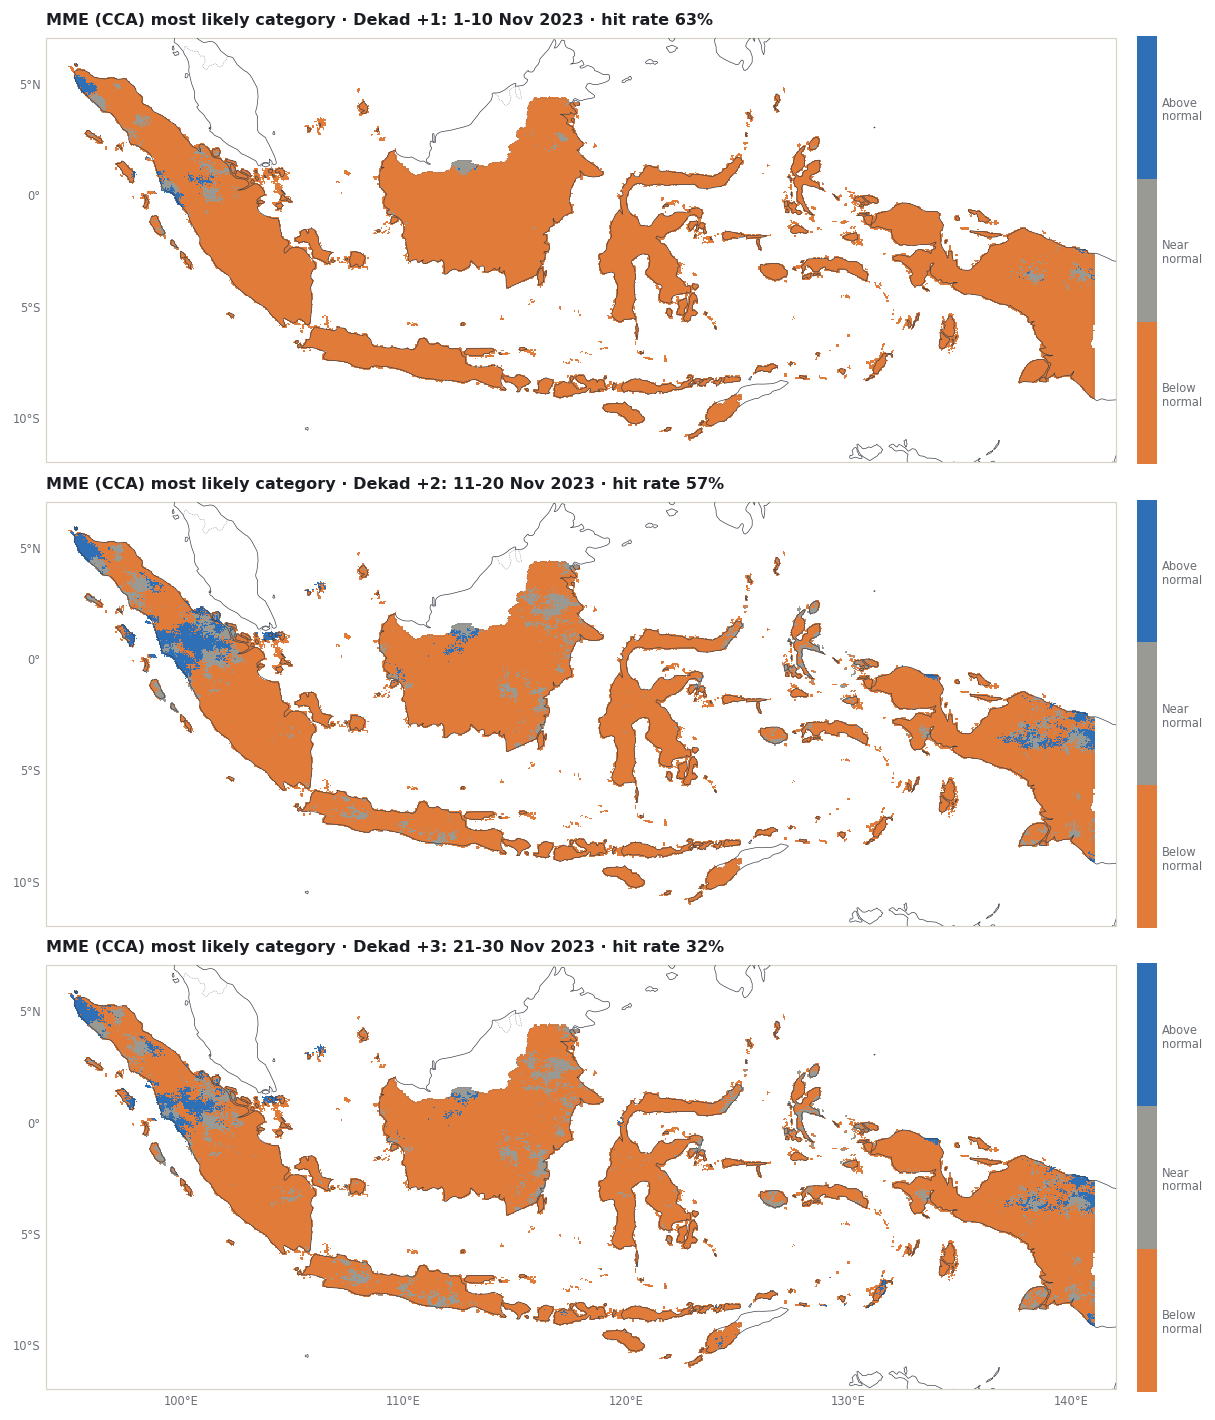

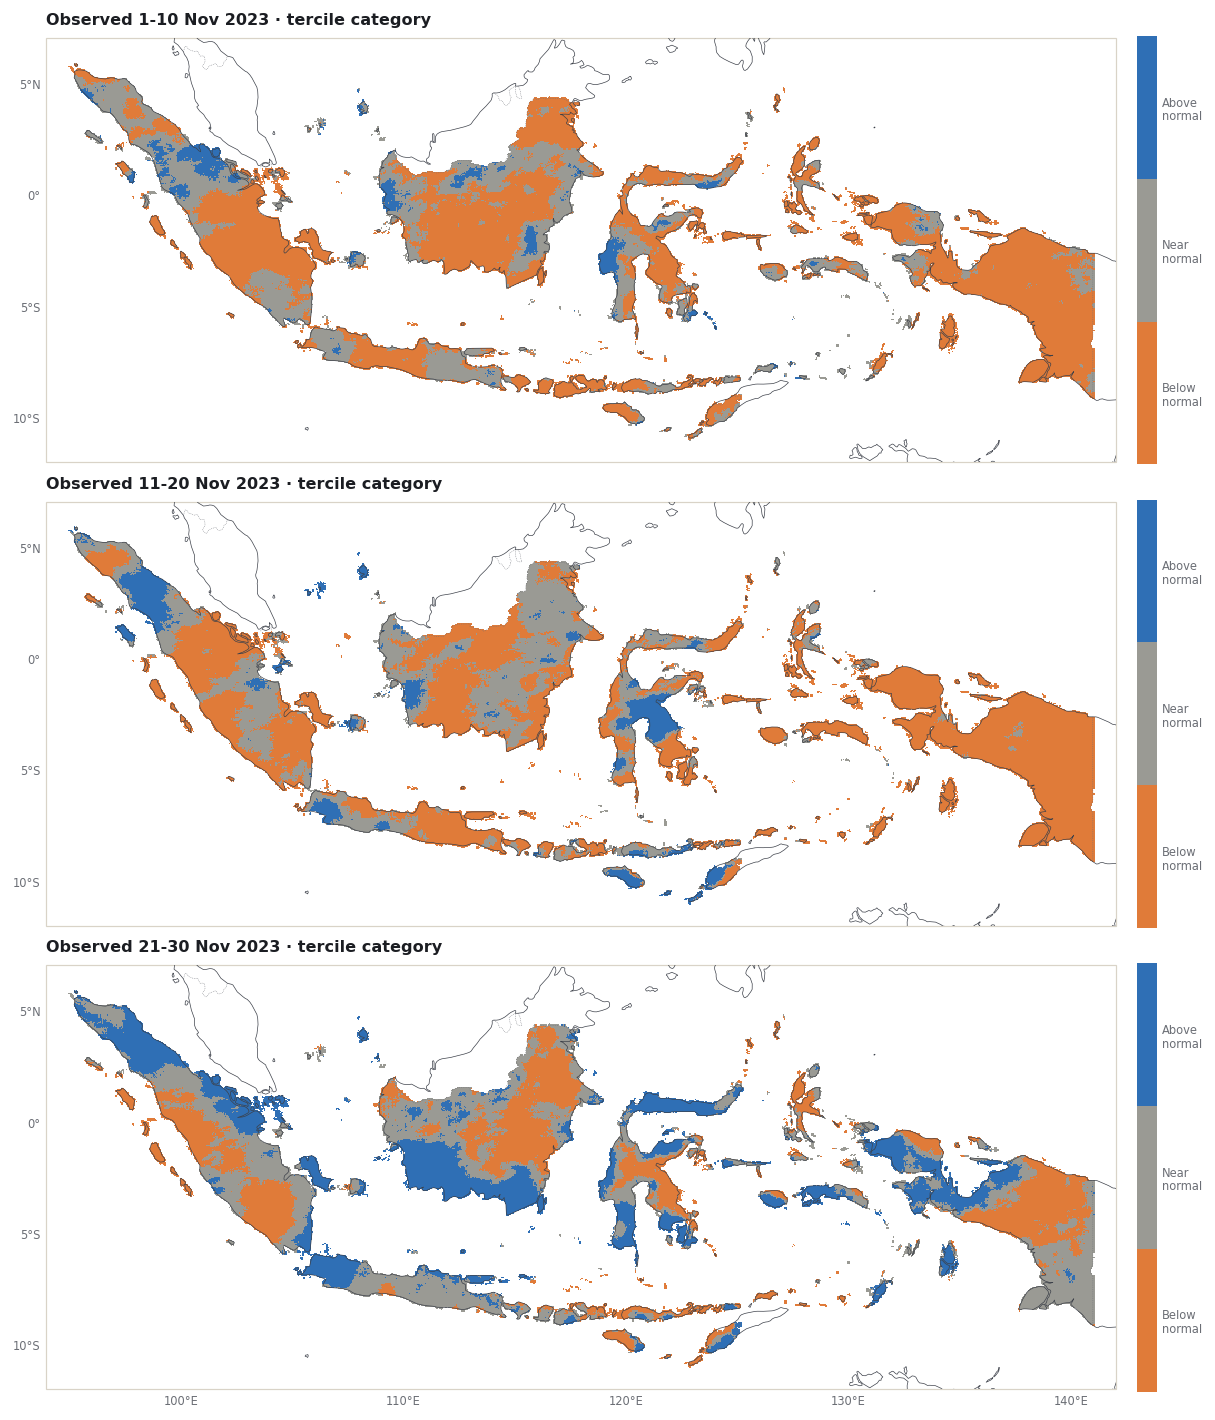

In [15]:
def category_bar(fig, image, ax):
    bar = figures.colorbar(fig, image, ax, "", ticks=[0, 1, 2])
    bar.ax.set_yticklabels(["Below\nnormal", "Near\nnormal", "Above\nnormal"])
    return bar


for kind, name in (("forecast", "mme-category-by-lead.png"), ("observed", "observed-by-lead.png")):
    fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
    for row, lead in enumerate(leads):
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
        if kind == "forecast":
            category_bar(fig, figures.category_map(ax, field(res[lead, "MME", "CCA"]["likely"])), ax)
            hit = forecast_2023.loc[(number[lead], "MME", "CCA"), "hit rate (%)"]
            ax.set_title(f"MME (CCA) most likely category · {lead_name[lead]}: {label[lead]} · hit rate {hit:.0f}%")
        else:
            category_bar(fig, figures.category_map(ax, field(observed[lead]["category"])), ax)
            ax.set_title(f"Observed {label[lead]} · tercile category")
    fig.savefig(assets / name)
    plt.show()

## 7. Flexible forecasts: probability of exceedance

A tercile map answers one question. The flexible forecast answers others: the
probability that the target's total exceeds a chosen amount. PyCPT's
`construct_flex_fcst` builds it from a deterministic forecast and its prediction error
variance, as a Student's t distribution. Its conventions are applied here to the
ensemble's anomaly and then moved to totals by adding the 2000-2016 mean of the
target dekad:

- forecast: Student's t with N degrees of freedom (N = the number of training
  targets), centred on the forecast, with scale sqrt((N - 2) / N × prediction error
  variance);
- climatology: a normal distribution with scale sqrt((N - 2) / N) × the standard
  deviation of the N training anomalies;
- thresholds: percentiles of the training anomalies (linear rule, as `Y.quantile`).

The cell below builds these fields, and for dekad +1 checks them against
`pycpt.construct_flex_fcst` itself. The default threshold is the **median**, so the
map reads as "chance of a wetter than median dekad"; 50% everywhere would be no
information.

In [16]:
import pycpt

percentiles = [10, 20, 33, 50, 67, 80, 90]
flex, quantiles, poe, flex_rows, dof = {}, {}, {}, [], {}
for lead in leads:
    r, o = res[lead, "MME", "CCA"], observed[lead]
    N = obs[lead].shape[0]
    dof[lead] = N
    shrink = (N - 2) / N
    flex[lead] = dict(forecast_mean=o["mean"] + r["f"], forecast_scale=np.sqrt(shrink * r["pev"]),
                      climatology_mean=o["mean"] + obs[lead].mean(0), climatology_scale=np.sqrt(shrink) * obs[lead].std(0))
    quantiles[lead] = o["mean"] + np.quantile(obs[lead], np.array(percentiles) / 100, axis=0)
    fx = flex[lead]
    poe[lead] = {p: student_t.sf(quantiles[lead][k], N, loc=fx["forecast_mean"], scale=fx["forecast_scale"]) * 100 for k, p in enumerate(percentiles)}
    median = quantiles[lead][percentiles.index(50)]
    flex_rows.append({"lead": number[lead], "target": label[lead], "degrees of freedom": N,
                      "mean chance of exceeding the median (%)": area_mean(poe[lead][50]),
                      "area with chance above 50% (%)": float(weight[poe[lead][50] > 50].sum() / weight.sum() * 100),
                      "area observed above the median (%)": float(weight[o["total"] > median].sum() / weight.sum() * 100)})
flex_table = pd.DataFrame(flex_rows).set_index("lead")

lead = leads[0]
with xr.open_dataarray(inputs / f"Y-{lead}.nc") as y:
    training = y.load()
py_flex = pycpt.construct_flex_fcst("CCA", {"transform_predictand": None, "tailoring": None}, field(res[lead, "MME", "CCA"]["f"]), 0.5, True,
                                    training, field(res[lead, "MME", "CCA"]["pev"]))
own = student_t.sf(np.quantile(obs[lead], 0.5, axis=0), dof[lead], loc=res[lead, "MME", "CCA"]["f"], scale=flex[lead]["forecast_scale"])
flex_check = {"exceedance probability (percentage points)": float(np.nanmax(abs(at_pixels(py_flex[0]) - own)) * 100),
              "forecast scale (mm)": float(np.nanmax(abs(at_pixels(py_flex[1]) - flex[lead]["forecast_scale"]))),
              "climatology scale (mm)": float(np.nanmax(abs(at_pixels(py_flex[2]) - flex[lead]["climatology_scale"]))),
              "degrees of freedom": int(py_flex[6]) - dof[lead]}
print(f"{lead_name[lead]}, this notebook minus pycpt.construct_flex_fcst, largest absolute difference:", {k: round(v, 6) for k, v in flex_check.items()})
flex_table.round(3)

~/miniforge3/envs/pycpt-tutorial/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Dekad +1, this notebook minus pycpt.construct_flex_fcst, largest absolute difference: {'exceedance probability (percentage points)': 1e-06, 'forecast scale (mm)': 0.0, 'climatology scale (mm)': 2.7e-05, 'degrees of freedom': 0}


,target,degrees of freedom,mean chance of exceeding the median (%),area with chance above 50% (%),area observed above the median (%)
lead,,,,,
1,1-10 Nov 2023,152,36.616,1.981,16.642
2,11-20 Nov 2023,151,43.086,8.993,19.305
3,21-30 Nov 2023,150,44.589,10.970,49.053


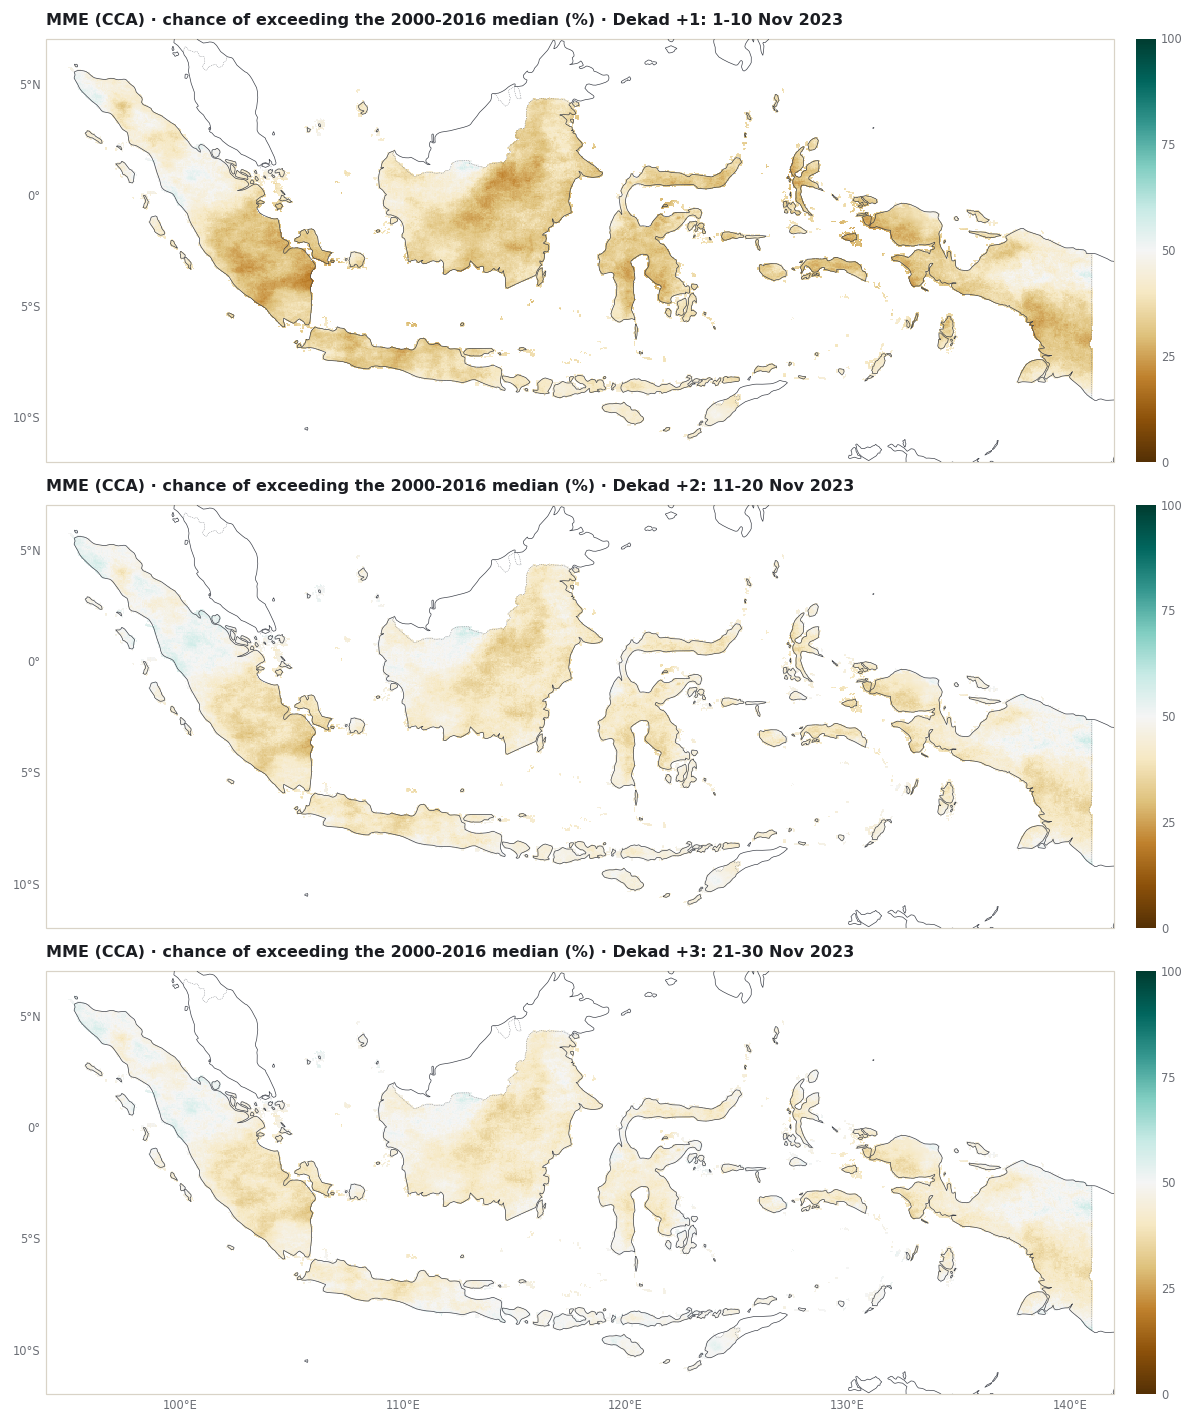

In [17]:
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, field(poe[lead][50]), cmap="BrBG", vmin=0, vmax=100)
    ax.set_title(f"MME (CCA) · chance of exceeding the 2000-2016 median (%) · {lead_name[lead]}: {label[lead]}")
    figures.colorbar(fig, image, ax, "", ticks=[0, 25, 50, 75, 100])
fig.savefig(assets / "poe-median-by-lead.png")
plt.show()

At one place the whole curve can be read. The pixel nearest Jakarta, dekad +1: the
forecast distribution against the climatology, as a probability of exceedance and as
a density. The climatology is drawn two ways: the training totals (steps) and the
normal distribution fitted to them.

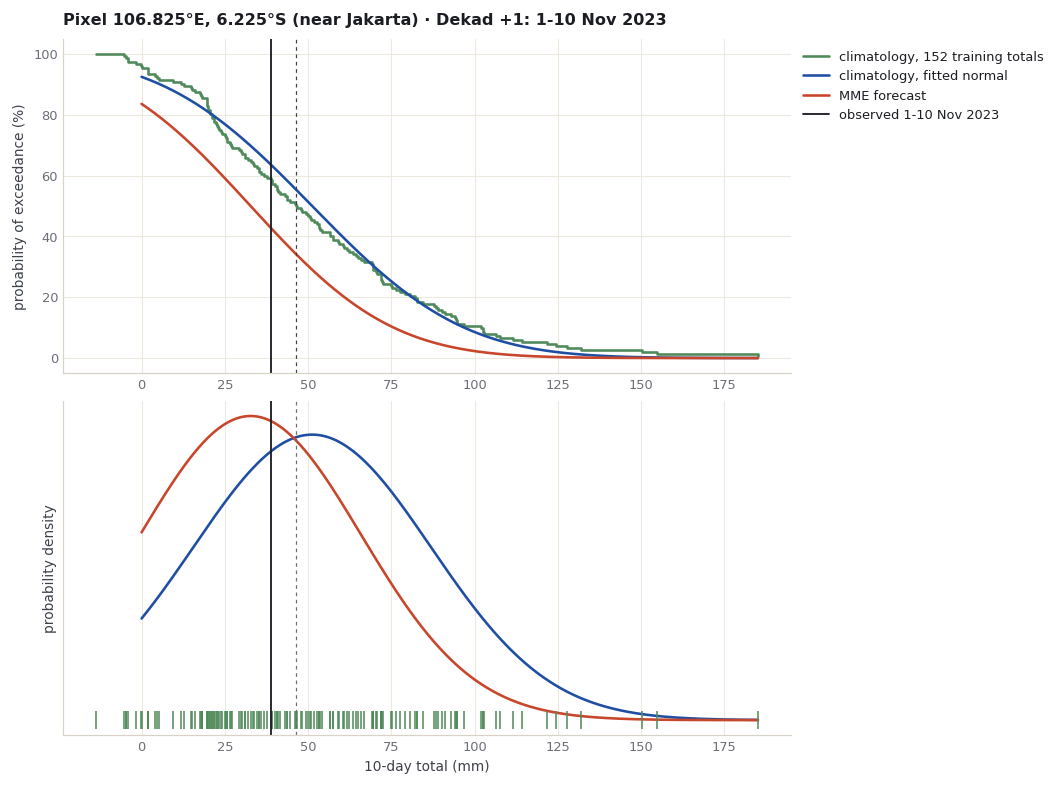

{'forecast_mean': 32.7, 'forecast_scale': 33.4, 'climatology_mean': 51.2, 'climatology_scale': 35.6} | observed: 38.9 | chance of exceeding the median: 34.3 %


In [18]:
point = int(np.argmin((pixel_lon - 106.85) ** 2 + (pixel_lat + 6.20) ** 2))
lead = leads[0]
fx = {k: float(v[point]) for k, v in flex[lead].items()}
history = np.sort(observed[lead]["mean"][point] + obs[lead][:, point])
median = float(quantiles[lead][percentiles.index(50)][point])
x = np.linspace(max(0, min(history.min(), fx["forecast_mean"] - 3 * fx["forecast_scale"])), max(history.max(), fx["forecast_mean"] + 3 * fx["forecast_scale"]), 400)
fig, grid = figures.stacked([3.0, 3.0], width=figures.MAP_WIDTH)
ax = fig.add_subplot(grid[0, 0])
ax.step(history, [(history >= v).mean() * 100 for v in history], where="post", color=figures.GREEN, label=f"climatology, {len(history)} training totals")
ax.plot(x, norm.sf(x, fx["climatology_mean"], fx["climatology_scale"]) * 100, color=figures.ACCENT, label="climatology, fitted normal")
ax.plot(x, student_t.sf(x, dof[lead], fx["forecast_mean"], fx["forecast_scale"]) * 100, color=figures.MARK, label="MME forecast")
ax.axvline(median, color=figures.INK_2 if hasattr(figures, "INK_2") else figures.MUTED, linewidth=.8, linestyle=(0, (3, 3)))
ax.axvline(observed[lead]["total"][point], color=figures.INK, linewidth=1.2, label=f"observed {label[lead]}")
ax.set(ylabel="probability of exceedance (%)", title=f"Pixel {pixel_lon[point]:.3f}°E, {abs(pixel_lat[point]):.3f}°S (near Jakarta) · {lead_name[lead]}: {label[lead]}")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax = fig.add_subplot(grid[1, 0])
ax.plot(x, norm.pdf(x, fx["climatology_mean"], fx["climatology_scale"]), color=figures.ACCENT)
ax.plot(x, student_t.pdf(x, dof[lead], fx["forecast_mean"], fx["forecast_scale"]), color=figures.MARK)
ax.plot(history, np.zeros_like(history), "|", color=figures.GREEN, markersize=12)
ax.axvline(median, color=figures.MUTED, linewidth=.8, linestyle=(0, (3, 3)))
ax.axvline(observed[lead]["total"][point], color=figures.INK, linewidth=1.2)
ax.set(xlabel=f"{meta['leads'][lead]['days']}-day total (mm)", ylabel="probability density", yticks=[])
fig.savefig(assets / "flex-point-lead1.png")
plt.show()
print({k: round(v, 1) for k, v in fx.items()}, "| observed:", round(float(observed[lead]["total"][point]), 1),
      "| chance of exceeding the median:", round(float(poe[lead][50][point]), 1), "%")

## 8. Save the results

Tables as CSV, the maps as one NetCDF file, and the browser files the story page
reads: a manifest, a shared pixel list and one small gzip-compressed binary file per
map, loaded only when a view needs it.

In [19]:
data_dir.mkdir(parents=True, exist_ok=True)
skill_table.round(4).to_csv(data_dir / "skill-by-lead.csv")
gain.round(4).to_csv(data_dir / "mme-against-members.csv")
leave_one_out.round(4).to_csv(data_dir / "leave-one-out.csv")
start_rule.to_csv(data_dir / "start-rule.csv")
membership.to_csv(data_dir / "membership.csv")
forecast_2023.round(4).to_csv(data_dir / "issued-2023-10-31-forecasts.csv")
targets_2023.round(4).to_csv(data_dir / "issued-2023-10-31-observed.csv")
mode_table.round(4).to_csv(data_dir / "eof-cca-modes.csv")
flex_table.round(4).to_csv(data_dir / "flexible-forecast.csv")
summary = {"issued": issue.date().isoformat(), "leads": leads,
           "targets": {lead: {"name": lead_name[lead], "label": label[lead], "first_day": meta["leads"][lead]["target_first_day"],
                               "last_day": meta["leads"][lead]["target_last_day"], "training_targets": len(target_years[lead])} for lead in leads},
           "members": {lead: [short(m) for m in members[lead]] for lead in leads}, "runs": meta["runs"],
           "training_target_years": meta["training_years"], "pixels": n, "grid": "native 0.05 degree",
           "settings": meta["settings"], "checks": {k: float(v) for k, v in gaps.items()},
           "flexible_forecast_check_first_lead": {k: float(v) for k, v in flex_check.items()},
           "no_model_cross_validated_pearson": {lead: round(v, 4) for lead, v in no_model_pearson.items()},
           "totals_set_to_zero_mme_cca": {lead: clipped[lead, "MME", "CCA"] for lead in leads},
           "fit_seconds": {f"{r['lead']}-{short(r['model'])}-{r['method']}": r["seconds"] for r in fit_records}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    maps[f"observed_{lead}"] = field(observed[lead]["total"])
    maps[f"observed_category_{lead}"] = field(observed[lead]["category"])
    maps[f"poe_median_mme_cca_{lead}"] = field(poe[lead][50])
    for method in ("CCA", "PCR"):
        r = res[lead, "MME", method]
        maps[f"mme_{method.lower()}_pearson_{lead}"] = field(r["pearson"])
        maps[f"mme_{method.lower()}_cv_rpss_{lead}"] = field(r["rpss"])
        maps[f"mme_{method.lower()}_forecast_{lead}"] = field(r["total"])
        maps[f"mme_{method.lower()}_most_likely_{lead}"] = field(r["likely"])
save_netcdf(maps, data_dir / "dekad-mme-2023-maps.nc", overwrite=True,
            metadata={"note": "Multi-model ensemble issued 31 October 2023, dekad +1 to dekad +3, training October-December 2000-2016; categories 0 below, 1 near, 2 above normal"})
for f in sorted(data_dir.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/dekad-mme-2023/dekad-mme-2023-maps.nc  (11452 kB)
docs/data/dekad-mme-2023/eof-cca-modes.csv  (1 kB)
docs/data/dekad-mme-2023/flexible-forecast.csv  (0 kB)
docs/data/dekad-mme-2023/issued-2023-10-31-forecasts.csv  (3 kB)
docs/data/dekad-mme-2023/issued-2023-10-31-observed.csv  (0 kB)
docs/data/dekad-mme-2023/leave-one-out.csv  (0 kB)
docs/data/dekad-mme-2023/membership.csv  (0 kB)
docs/data/dekad-mme-2023/mme-against-members.csv  (1 kB)
docs/data/dekad-mme-2023/skill-by-lead.csv  (2 kB)
docs/data/dekad-mme-2023/start-rule.csv  (0 kB)
docs/data/dekad-mme-2023/summary.json  (4 kB)


In [20]:
def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


def encode(values, kind, scale, offset=0.0):
    v = np.round((np.asarray(values, dtype="float64") - offset) * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    if kind == "i8":
        return np.where(np.isfinite(v), np.clip(v, -127, 127), -128).astype("i1").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


field_dir = assets / "fields"
field_dir.mkdir(parents=True, exist_ok=True)
for old in field_dir.glob("*"):
    old.unlink()
layout = {"skill": [["value", "u8", 100, -1]],
          "obs": [["total", "u16", 10], ["mean", "u16", 10], ["category", "u8", 1]],
          "fc": [["total", "u16", 10], ["below", "u8", 2], ["above", "u8", 2]],
          "flex": [["mu", "i16", 10], ["scale", "u16", 10], ["cmu", "u16", 10], ["cscale", "u16", 10]],
          "quant": [[f"q{p}", "i16", 10] for p in percentiles],
          "yeof": [[f"m{k}", "i8", 127] for k in (1, 2, 3)], "ycca": [[f"m{k}", "i8", 127] for k in (1, 2)]}


def write(name, kind, parts):
    spec = layout[kind]
    assert len(spec) == len(parts)
    blob = b"".join(encode(v, s[1], s[2], s[3] if len(s) > 3 else 0.0) for v, s in zip(parts, spec))
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(blob, 9, mtime=0))


def unit(a):
    return a / np.nanmax(abs(a))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
target_info, issue_targets = [], []
for lead in leads:
    o, days = observed[lead], meta["leads"][lead]["days"]
    target_info.append({"lead": number[lead], "label": label[lead], "pycpt": f"days {meta['leads'][lead]['first_day']} to {meta['leads'][lead]['first_day'] + days - 1} after the issue date",
                        "start": meta["leads"][lead]["target_first_day"], "end": f"{last_day[lead] + pd.Timedelta(days=1):%Y-%m-%d}"})
    issue_targets.append({"lead": lead, "start": meta["leads"][lead]["target_first_day"], "days": int(days)})
    write(f"obs-{lead}", "obs", [o["total"], o["mean"], o["category"]])
    fx = flex[lead]
    write(f"flex-{lead}", "flex", [fx["forecast_mean"], fx["forecast_scale"], fx["climatology_mean"], fx["climatology_scale"]])
    write(f"quant-{lead}", "quant", list(quantiles[lead]))
    y_eof = patterns[lead, "GEFSv12_CPC"].y_eof_loadings.values.astype("float64")
    write(f"yeof-{lead}", "yeof", [unit(y_eof[k]) for k in range(3)])
    lead_patterns = {"years": [int(y) for y in target_years[lead]], "labels": [f"{t:%d %b %Y}" for t in target_dates[lead]], "models": {}}
    for name in names[lead]:
        for method in ("CCA", "PCR"):
            r = res[lead, name, method]
            write(f"skill-{short(name)}-{method}-pearson-{lead}", "skill", [r["pearson"]])
            write(f"skill-{short(name)}-{method}-rpss-{lead}", "skill", [np.clip(r["rpss"], -1, 1)])
            write(f"fc-{short(name)}-{method}-{lead}", "fc", [r["total"], r["p"][0], r["p"][2]])
        write(f"skill-{short(name)}-raw-pearson-{lead}", "skill", [res[lead, name, "raw"]["pearson"]])
        if name == "MME":
            continue
        ds = patterns[lead, name]
        y_cca = ds.y_cca_loadings.values.astype("float64")
        write(f"ycca-{short(name)}-{lead}", "ycca", [unit(y_cca[k]) for k in range(2)])
        clean = lambda a: [None if not np.isfinite(v) else round(float(v), 3) for v in np.asarray(a).ravel()]
        loadings = lambda v, k: [None if not np.isfinite(q) else round(float(q), 2) for q in unit(ds[v].sel(Mode=k).transpose("Yx", "Xx").values).ravel()]
        lead_patterns["models"][short(name)] = {
            "lat": [float(v) for v in ds["Yx"].values], "lon": [float(v) for v in ds["Xx"].values],
            "xEof": [loadings("x_eof_loadings", k) for k in (1, 2, 3)], "xCca": [loadings("x_cca_loadings", k) for k in (1, 2)],
            "xEofScores": [clean(ds.x_eof_scores.sel(Mode=k)) for k in (1, 2, 3)], "yEofScores": [clean(ds.y_eof_scores.sel(Mode=k)) for k in (1, 2, 3)],
            "xCcaScores": [clean(ds.x_cca_scores.sel(Mode=k)) for k in (1, 2)], "yCcaScores": [clean(ds.y_cca_scores.sel(Mode=k)) for k in (1, 2)],
            "xVariance": clean(ds.x_explained_variance.sel(Mode=[1, 2, 3])), "yVariance": clean(ds.y_explained_variance.sel(Mode=[1, 2, 3])),
            "canonical": [round(float(mode_table.loc[(number[lead], short(name)), f"canonical correlation {k}"]), 3) for k in (1, 2)]}
    (assets / f"patterns-{lead}.json").write_text(json.dumps(lead_patterns, separators=(",", ":"), allow_nan=False) + "\n")

values = np.concatenate([observed[lead]["total"] for lead in leads] + [res[lead, "MME", "CCA"]["total"] for lead in leads])
top = float(np.ceil(np.nanpercentile(values, 99) / 50) * 50)
counts = sorted({len(target_years[lead]) for lead in leads})
manifest = {
    "grid": {"west": round(float(grid_X.min()) - .025, 3), "north": round(float(grid_Y.max()) + .025, 3), "step": 0.05,
             "nx": int(grid_mask.sizes["X"]), "ny": int(grid_mask.sizes["Y"]), "pixels": n},
    "kind": "dekad", "periodWord": "dekad", "axisDays": 35, "outcomeLabel": "November 2023", "sampleUnit": "training targets",
    "issue": {"date": issue.date().isoformat(), "label": f"{issue.day} {issue:%b %Y}"},
    "issues": [{"issued": issue.date().isoformat(), "label": f"{issue:%a} {issue.day} {issue:%b %Y}", "targets": issue_targets}],
    "timelineTitle": "the next three dekads",
    "timelineHint": "Issued at 00 UTC on the last day of a dekad. Bars are the target dekads in days after the issue date; every model forecasts the same calendar days, from its own latest run. Hover for dates.",
    "leads": order, "leadKeys": leads, "methods": ["CCA", "PCR"], "unit": "mm",
    "leadNames": [f"{lead_name[lead]} · {label[lead]}" for lead in leads], "leadShort": [lead_name[lead] for lead in leads],
    "days": {lead: meta["leads"][lead]["days"] for lead in leads}, "firstDay": {lead: meta["leads"][lead]["first_day"] for lead in leads},
    "training": "2000-2016", "sample": f"the {counts[0]} to {counts[-1]} training targets of October-December 2000-2016",
    "cellText": f"Indonesia's {n:,} pixels at 0.05°", "targets": target_info,
    "models": [short(m) for m in models] + ["MME"], "members": {lead: [short(m) for m in members[lead]] for lead in leads},
    "modelColors": {**model_colours, "MME": figures.INK},
    "predictorBox": predictor_extent, "percentiles": percentiles, "flexDof": {lead: int(dof[lead]) for lead in leads},
    "layout": layout, "rainMax": top, "rainLegend": "mm in the dekad",
    "skillTable": records(skill_table.reset_index().round(4)),
    "gain": records(gain.reset_index().round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "references": records(targets_2023.reset_index().round(3)),
}
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(q.stat().st_size for q in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"pattern files {sum(q.stat().st_size for q in assets.glob('patterns-*.json')) / 1e6:.1f} MB; colour scale up to {top:.0f} mm")

69,638 pixels; 145 field files, 14.6 MB in total (largest 715 kB); pattern files 1.3 MB; colour scale up to 200 mm
